# Étape 1 – Visualisation des distributions et corrélations (dataset consolidé)

**Source unique** : `data/consolidated_yield.csv` (déjà nettoyé et dédoublonné, aucun traitement supplémentaire ici).
**Config** : `config.yaml` à la racine du projet (seed, chemins, traduction des cultures).

Plan : 1) aperçu · 2) distributions · 3) corrélations · 4) importance des variables · 5) synthèse.

Les figures destinées au rapport sont exportées dans `reports/figures/`.

In [19]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, yaml
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import r2_score

# Notebook dans notebooks/ -> la racine du projet est un cran au-dessus
ROOT = Path.cwd().parent
cfg = yaml.safe_load(open(ROOT / "config.yaml", encoding="utf-8"))
SEED = cfg["seed"]
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / cfg["paths"]["clean"])

# Cultures en français (dictionnaire du config.yaml)
df["culture"] = df["item"].map(cfg["item_fr"]).fillna(df["item"])

# Rendement en t/ha (1 t/ha = 10 000 hg/ha) + cible log si absente
if "yield_t_ha" not in df:
    df["yield_t_ha"] = df["yield_hg_ha"] / 10_000
if "log_yield" not in df:
    df["log_yield"] = np.log(df["yield_t_ha"])

LABELS = {
    "yield_t_ha": "Rendement (t/ha)",
    "log_yield": "Rendement (échelle log)",
    "rain_mm": "Pluie (mm/an)",
    "temp_c": "Température moyenne (°C)",
    "pest_kg_ha": "Pesticides (kg/ha)",
    "year": "Année",
    "item": "Type de culture",
    "area": "Pays"
}
sns.set_theme(style="whitegrid", context="notebook")
GREEN = "#4C8C4A"

def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Aperçu

In [2]:
print(f"{df.shape[0]:,} lignes · {df['area'].nunique()} pays · {df['culture'].nunique()} cultures · "
      f"{int(df['year'].min())}–{int(df['year'].max())}")
print("Valeurs manquantes :", int(df.isna().sum().sum()))
df[["yield_t_ha", "rain_mm", "temp_c", "pest_kg_ha"]].describe().round(2).rename(columns=LABELS)

13,130 lignes · 101 pays · 10 cultures · 1990–2013
Valeurs manquantes : 0


,Rendement (t/ha),Pluie (mm/an),Température moyenne (°C),Pesticides (kg/ha)
count,13130.00,13130.00,13130.00,13130.00
mean,7.10,1157.24,19.84,2.48
std,7.91,743.62,6.66,4.22
min,0.00,51.00,1.30,0.00
25%,1.80,608.00,15.67,0.20
50%,3.95,1083.00,20.62,0.93
75%,9.72,1651.00,25.78,3.05
max,50.14,3240.00,30.42,36.66


## 2. Distributions

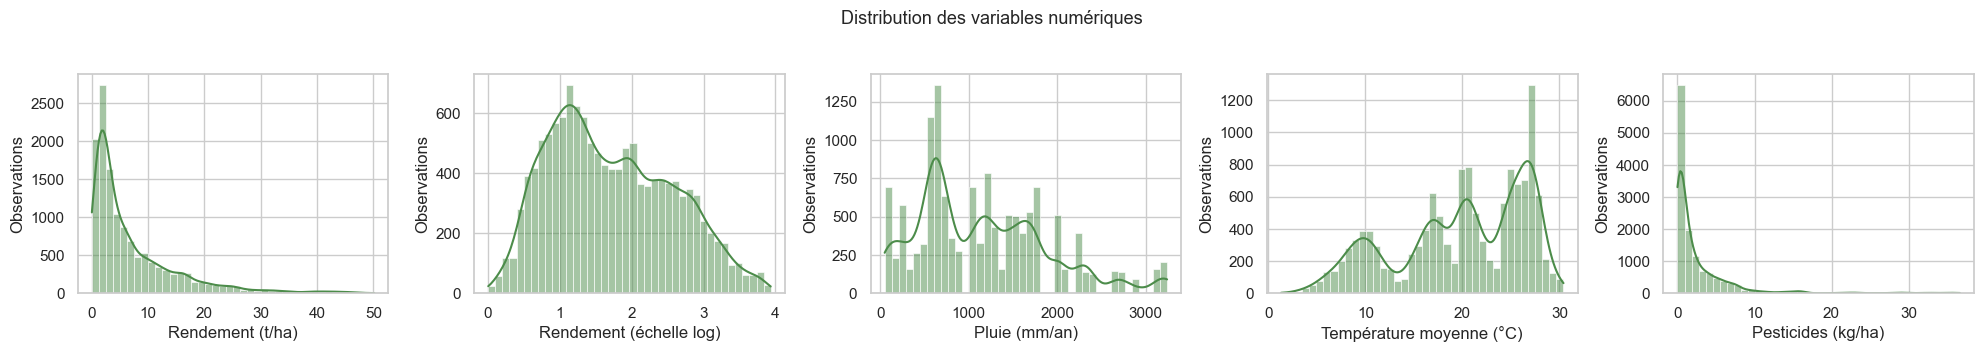

In [3]:
cols = ["yield_t_ha", "log_yield", "rain_mm", "temp_c", "pest_kg_ha"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
for ax, c in zip(axes, cols):
    sns.histplot(df[c], bins=40, kde=True, color=GREEN, ax=ax)
    ax.set_xlabel(LABELS[c]); ax.set_ylabel("Observations")
fig.suptitle("Distribution des variables numériques", y=1.03, fontsize=13)
plt.tight_layout(); save("fig01_distributions"); plt.show()

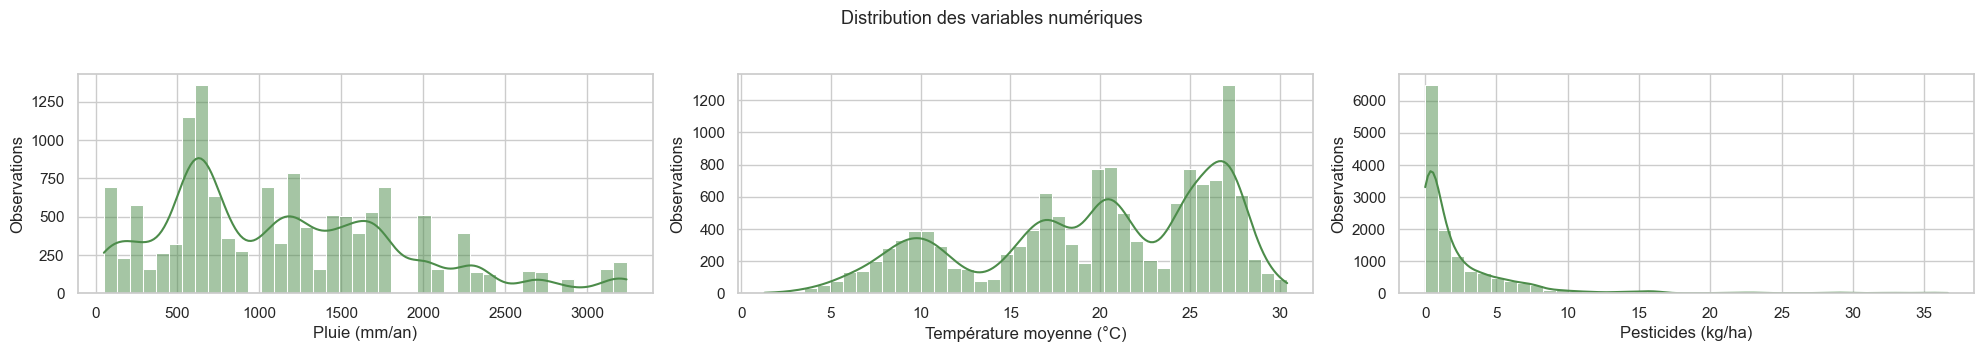

In [25]:
cols = ["rain_mm", "temp_c", "pest_kg_ha"]
fig, axes = plt.subplots(1, 3, figsize=(20, 3.4))
for ax, c in zip(axes, cols):
    sns.histplot(df[c], bins=40, kde=True, color=GREEN, ax=ax)
    ax.set_xlabel(LABELS[c]); ax.set_ylabel("Observations")
fig.suptitle("Distribution des variables numériques", y=1.03, fontsize=13)
plt.tight_layout(); save("fig01_distributions"); plt.show()

Le rendement est très étalé à droite (quelques cultures dépassent 20 t/ha) : le passage au **log** rend la distribution
plus symétrique, c'est la raison du choix de `log_yield` comme cible pour la modélisation.

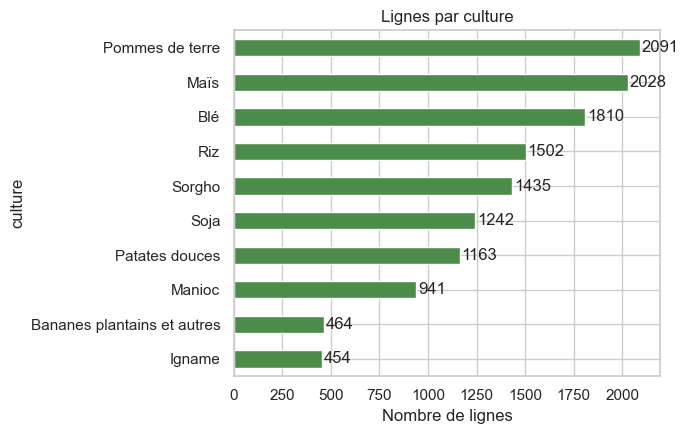

In [24]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, yaml

ROOT = Path.cwd().parent
cfg = yaml.safe_load(open(ROOT / "config.yaml", encoding="utf-8"))
df = pd.read_csv(ROOT / cfg["paths"]["clean"])
df["culture"] = df["item"].map(cfg["item_fr"]).fillna(df["item"])

n = df["culture"].value_counts().sort_values()
ax = n.plot.barh(color="#4C8C4A", figsize=(7, 4.5))
for i, v in enumerate(n): ax.text(v + 10, i, v, va="center")
ax.set_xlabel("Nombre de lignes"); ax.set_title("Lignes par culture")
plt.tight_layout(); plt.show()

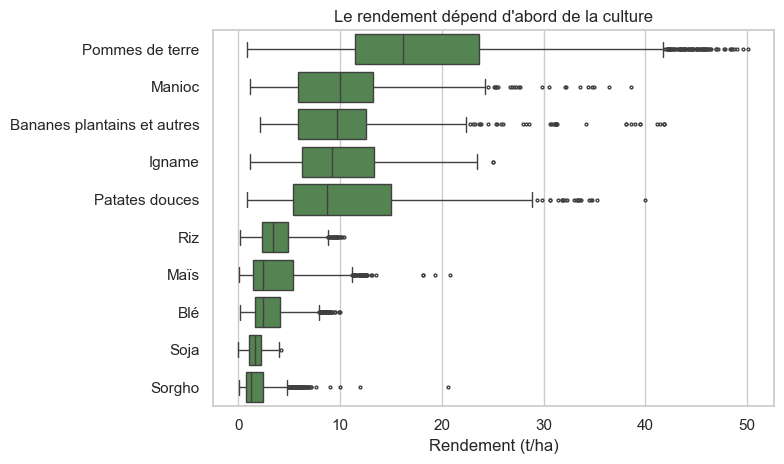

In [4]:
order = df.groupby("culture")["yield_t_ha"].median().sort_values(ascending=False).index
plt.figure(figsize=(8, 4.8))
sns.boxplot(data=df, x="yield_t_ha", y="culture", order=order, color=GREEN,
            fliersize=2, linewidth=1)
plt.xlabel("Rendement (t/ha)"); plt.ylabel("")
plt.title("Le rendement dépend d'abord de la culture")
plt.tight_layout(); save("fig01b_boxplot_rendement"); plt.show()   # annexe

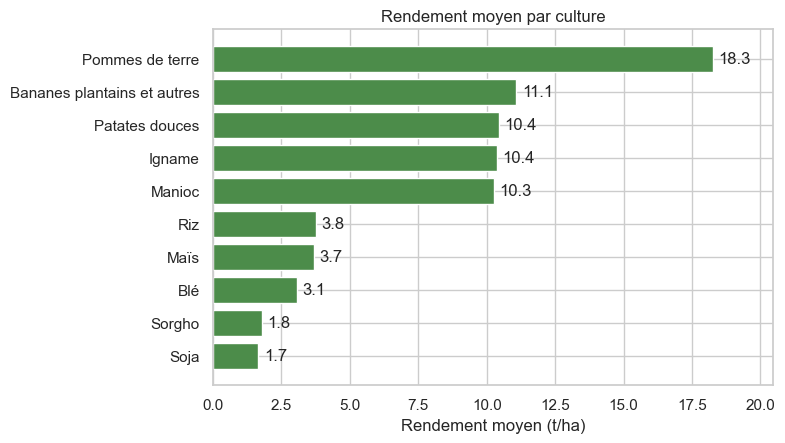

In [5]:
m = df.groupby("culture")["yield_t_ha"].mean().sort_values()
plt.figure(figsize=(8, 4.6))
plt.barh(m.index, m.values, color=GREEN)
for i, v in enumerate(m.values):
    plt.text(v + 0.2, i, f"{v:.1f}", va="center")
plt.xlabel("Rendement moyen (t/ha)"); plt.xlim(0, m.max() * 1.12)
plt.title("Rendement moyen par culture")
plt.tight_layout(); save("fig02_rendement_moyen_par_culture"); plt.show()   # -> RAPPORT

**Attention** : des tonnes par hectare ne se comparent pas d'une culture à l'autre (une tonne de pommes de terre, riche en eau,
n'a ni la même valeur ni le même apport calorique qu'une tonne de sorgho). Classer les cultures sur le rendement brut
favoriserait toujours les mêmes ; d'où l'intérêt de comparer chaque culture **à sa propre référence** (écart en % vs son rendement moyen)
et, plus tard, de passer en valeur économique.

## 3. Corrélations

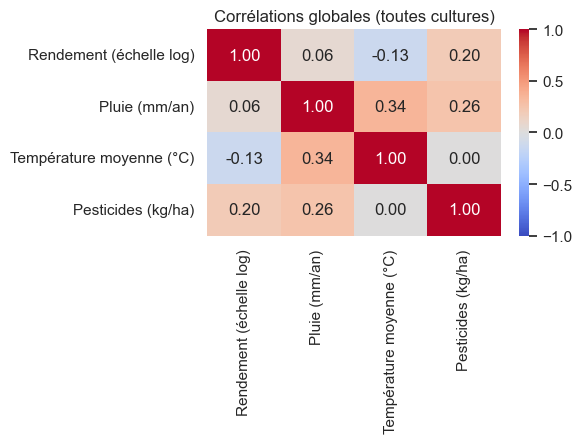

In [27]:
num = ["log_yield", "rain_mm", "temp_c", "pest_kg_ha"]
corr = df[num].corr().rename(index=LABELS, columns=LABELS)
plt.figure(figsize=(6, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Corrélations globales (toutes cultures)")
plt.tight_layout(); save("fig03_correlations_globales"); plt.show()

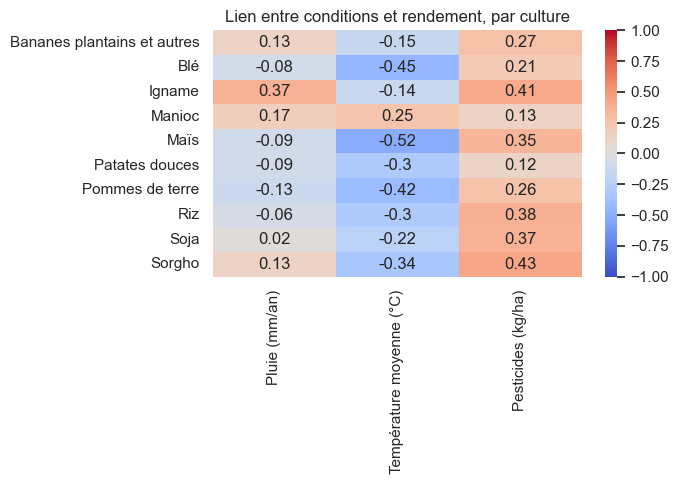

In [7]:
corr_c = (df.groupby("culture")[num].corr()["log_yield"].unstack()
            .drop(columns="log_yield").round(2))
corr_c.columns = [LABELS[c] for c in corr_c.columns]
plt.figure(figsize=(7, 5))
sns.heatmap(corr_c, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.ylabel(""); plt.title("Lien entre conditions et rendement, par culture")
plt.tight_layout(); save("fig04_correlations_par_culture"); plt.show()   # -> RAPPORT

**Lecture** : corrélation proche de 0 = pas de lien linéaire net ; positive = le rendement monte avec la variable.
Attention, les corrélations restent **modérées** et ne prouvent pas une causalité : pluie et température sont des moyennes
par pays, donc elles reflètent aussi les différences entre pays (climat, niveau d'équipement, etc.).

## 4. Importance des variables

Modèle RandomForest, validé avec des **pays jamais vus à l'entraînement** (`GroupKFold` par pays) : c'est l'estimation honnête
de ce qu'on peut attendre sur une nouvelle parcelle. `area` est volontairement exclu de ce modèle : un pays absent de
l'entraînement ne peut pas être exploité, et sa permutation donnerait une importance de 0 par pur artefact.
L'importance est mesurée par **permutation de blocs** : on mélange toutes les colonnes d'une variable (ex. les 10 colonnes de
la culture ensemble) et on regarde de combien le R² chute.

In [8]:
FEATS = ["item", "rain_mm", "temp_c", "pest_kg_ha"]   # mêmes variables que le modèle final
X = pd.get_dummies(df[FEATS], columns=["item"])
y = df["log_yield"]
blocks = {"item": [c for c in X if c.startswith("item_")],
          "rain_mm": ["rain_mm"], "temp_c": ["temp_c"],
          "pest_kg_ha": ["pest_kg_ha"]}

def make_rf():
    return RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEED)

rng = np.random.default_rng(SEED)
r2_folds, drops = [], {k: [] for k in blocks}
for tr, te in GroupKFold(n_splits=5).split(X, y, groups=df["area"]):
    rf = make_rf().fit(X.iloc[tr], y.iloc[tr])
    Xte, yte = X.iloc[te], y.iloc[te]
    base = r2_score(yte, rf.predict(Xte))
    r2_folds.append(base)
    for name, cols_ in blocks.items():
        d = []
        for _ in range(3):
            Xp = Xte.copy()
            Xp[cols_] = Xp[cols_].iloc[rng.permutation(len(Xp))].values
            d.append(base - r2_score(yte, rf.predict(Xp)))
        drops[name].append(np.mean(d))

r2_new_countries = np.mean(r2_folds)
print(f"R² sur pays jamais vus : {r2_new_countries:.2f} ± {np.std(r2_folds):.2f} (5 folds)")

imp = pd.Series({k: np.mean(v) for k, v in drops.items()}).clip(lower=0)
imp_pct = (imp / imp.sum() * 100).sort_values()

R² sur pays jamais vus : 0.64 ± 0.08 (5 folds)


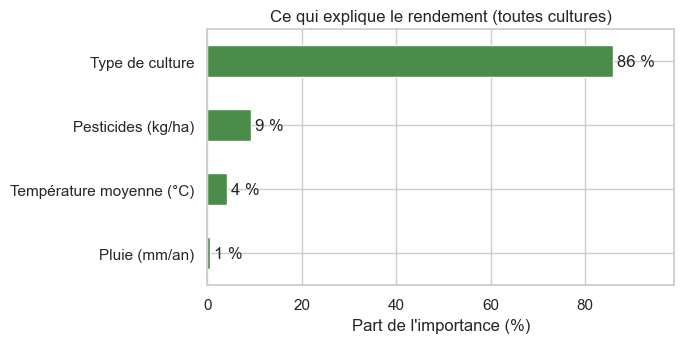

In [9]:
plt.figure(figsize=(7, 3.6))
ax = imp_pct.rename(index=LABELS).plot.barh(color=GREEN)
for p in ax.patches:
    ax.text(p.get_width() + 0.8, p.get_y() + p.get_height() / 2, f"{p.get_width():.0f} %", va="center")
plt.xlabel("Part de l'importance (%)"); plt.xlim(0, max(imp_pct) * 1.15)
plt.title("Ce qui explique le rendement (toutes cultures)")
plt.tight_layout(); save("fig05_importance_globale"); plt.show()   # annexe

In [10]:
# Contraste : split aléatoire AVEC le pays (fuite entre années d'un même pays -> score optimiste)
Xa = pd.get_dummies(df[FEATS + ["area"]], columns=["item", "area"])
r2_rand = np.mean([r2_score(y.iloc[te], make_rf().fit(Xa.iloc[tr], y.iloc[tr]).predict(Xa.iloc[te]))
                   for tr, te in KFold(5, shuffle=True, random_state=SEED).split(Xa)])
print(f"R² split aléatoire avec pays : {r2_rand:.2f}  vs  pays jamais vus : {r2_new_countries:.2f}")

R² split aléatoire avec pays : 0.95  vs  pays jamais vus : 0.64


### Importance des variables **par culture**
Un modèle par culture (pluie, température, pesticides), toujours validé sur des **pays jamais vus**. Chaque ligne se lit
comme une répartition à 100 % entre les 3 variables. Le **R²** (entre parenthèses) indique si le modèle tient la route pour
cette culture : s'il est faible, la répartition est peu fiable. La flèche donne le **sens** du lien (signe de la corrélation).

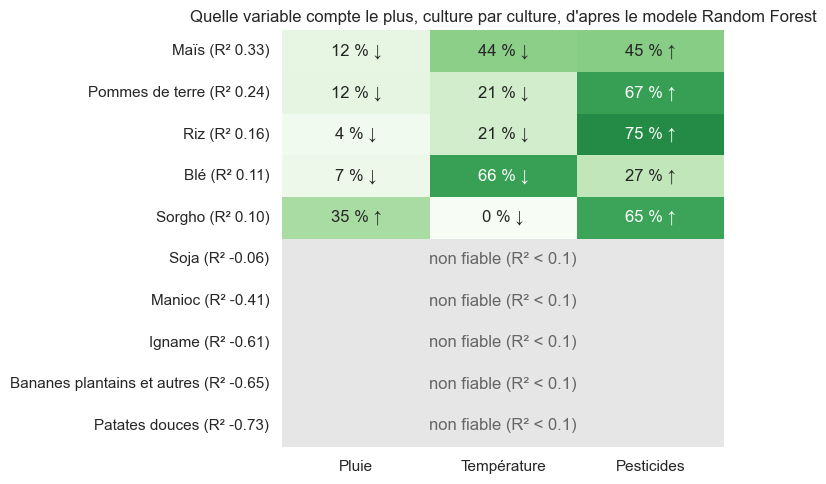

In [28]:
FE = ["rain_mm", "temp_c", "pest_kg_ha"]
R2_MIN = 0.10   # en dessous, le modèle de la culture n'est pas fiable
rng2 = np.random.default_rng(SEED)
rows, r2s = {}, {}
for cult, g in df.groupby("culture"):
    g = g.reset_index(drop=True)
    Xg, yg = g[FE], g["log_yield"]
    d, r2 = {f: [] for f in FE}, []
    for tr, te in GroupKFold(n_splits=5).split(Xg, yg, groups=g["area"]):
        rf = make_rf().fit(Xg.iloc[tr], yg.iloc[tr])
        Xte, yte = Xg.iloc[te], yg.iloc[te]
        base = r2_score(yte, rf.predict(Xte)); r2.append(base)
        for f in FE:
            dd = []
            for _ in range(3):
                Xp = Xte.copy(); Xp[f] = rng2.permutation(Xp[f].values)
                dd.append(base - r2_score(yte, rf.predict(Xp)))
            d[f].append(np.mean(dd))
    rows[cult] = {f: max(np.mean(v), 0) for f, v in d.items()}
    r2s[cult] = np.mean(r2)

imp_c = pd.DataFrame(rows).T
imp_c_pct = imp_c.div(imp_c.sum(axis=1), axis=0).fillna(0) * 100
imp_c_pct = imp_c_pct.loc[pd.Series(r2s).sort_values(ascending=False).index]

sign = np.sign(corr_c.loc[imp_c_pct.index, [LABELS[f] for f in FE]].values)
annot = (imp_c_pct.round(0).astype(int).astype(str) + " %").values + np.where(sign > 0, " ↑", " ↓")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.set_facecolor("#e6e6e6"); ax.grid(False)
bad = np.array([r2s[c] < R2_MIN for c in imp_c_pct.index])
mask = np.repeat(bad[:, None], len(FE), axis=1)
short = {"rain_mm": "Pluie", "temp_c": "Température", "pest_kg_ha": "Pesticides"}
sns.heatmap(imp_c_pct.rename(columns=short), annot=annot, fmt="", cmap="Greens", vmin=0, vmax=100,
            cbar=False, mask=mask, ax=ax)
for i, b in enumerate(bad):
    if b: ax.text(1.5, i + .5, f"non fiable (R² < {R2_MIN})", ha="center", va="center", color="#666")
ax.set_yticks(np.arange(len(imp_c_pct)) + .5)
ax.set_yticklabels([f"{c} (R² {r2s[c]:.2f})" for c in imp_c_pct.index], rotation=0)
ax.set_ylabel(""); ax.set_title("Quelle variable compte le plus, culture par culture, d'apres le modele Random Forest")
plt.tight_layout(); save("fig06_importance_par_culture"); plt.show()   # -> RAPPORT

## 5. Synthèse

In [13]:
med = df.groupby("culture")["yield_t_ha"].median().sort_values()
g = corr.loc[LABELS["log_yield"]].drop(LABELS["log_yield"])
top = imp_pct.sort_values(ascending=False)
nm = lambda k: LABELS[k].split(" (")[0].lower()

print("SYNTHÈSE (valeurs calculées)")
print(f"• Rendement médian : de {med.iloc[0]:.1f} t/ha ({med.index[0]}) à {med.iloc[-1]:.1f} t/ha ({med.index[-1]}).")
print("• Corrélations globales avec le rendement (log) : " +
      ", ".join(f"{k.split(' (')[0].lower()} {v:+.2f}" for k, v in g.items()) + ".")
print(f"• Variable la plus influente : {nm(top.index[0])} ({top.iloc[0]:.0f} % de l'importance), "
      f"puis {nm(top.index[1])} ({top.iloc[1]:.0f} %) et {nm(top.index[2])} ({top.iloc[2]:.0f} %).")
ok = [c for c in imp_c_pct.index if r2s[c] >= R2_MIN]
print(f"• Cultures modélisables de façon fiable (R² ≥ {R2_MIN}) : {', '.join(ok) or 'aucune'} ; les autres dépendent surtout du pays.")
for f in FE if ok else []:
    c = imp_c_pct.loc[ok, f].idxmax()
    print(f"• Culture la plus sensible à {LABELS[f].split(' (')[0].lower()} : {c} ({imp_c_pct.loc[c, f]:.0f} % de son importance, R² {r2s[c]:.2f}).")
print(f"• Fiabilité : R² = {r2_new_countries:.2f} sur pays jamais vus (contre {r2_rand:.2f} avec un split aléatoire, trop optimiste).")

SYNTHÈSE (valeurs calculées)
• Rendement médian : de 1.2 t/ha (Sorgho) à 16.2 t/ha (Pommes de terre).
• Corrélations globales avec le rendement (log) : pluie +0.06, température moyenne -0.13, pesticides +0.20.
• Variable la plus influente : type de culture (86 % de l'importance), puis pesticides (9 %) et température moyenne (4 %).
• Cultures modélisables de façon fiable (R² ≥ 0.1) : Maïs, Pommes de terre, Riz, Blé, Sorgho ; les autres dépendent surtout du pays.
• Culture la plus sensible à pluie : Sorgho (35 % de son importance, R² 0.10).
• Culture la plus sensible à température moyenne : Blé (66 % de son importance, R² 0.11).
• Culture la plus sensible à pesticides : Riz (75 % de son importance, R² 0.16).
• Fiabilité : R² = 0.64 sur pays jamais vus (contre 0.95 avec un split aléatoire, trop optimiste).


### Figures à garder dans le rapport (2 suffisent)
| Figure | Message pour le lecteur non technique |
|---|---|
| `fig02_rendement_moyen_par_culture.png` | Le rendement brut varie énormément d'une culture à l'autre : on ne peut pas classer les cultures sur les t/ha seuls. |
| `fig06_importance_par_culture.png` | Selon la culture, ce n'est pas la même variable (pluie, température, pesticides) qui compte le plus, avec un indicateur de fiabilité. |

Annexe (restent dans le notebook) : `fig01` distributions, `fig01b` boxplot, `fig03` corrélations globales, `fig04` corrélations par culture, `fig05` importance globale.